In [41]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import linear_sum_assignment
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn_extra.cluster import KMedoids
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

RANDOM_STATE = 42
K_RANGE = range(2, 11)
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

In [42]:
df = pd.read_csv("CC GENERAL.csv")
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [44]:
print(df.dtypes.to_string())
print("\nDuplicate customer IDs:", df["CUST_ID"].duplicated().sum())
print("\nMissing values:")
print(df.isna().sum()[df.isna().sum() > 0].to_string())

CUST_ID                              object
BALANCE                             float64
BALANCE_FREQUENCY                   float64
PURCHASES                           float64
ONEOFF_PURCHASES                    float64
INSTALLMENTS_PURCHASES              float64
CASH_ADVANCE                        float64
PURCHASES_FREQUENCY                 float64
ONEOFF_PURCHASES_FREQUENCY          float64
PURCHASES_INSTALLMENTS_FREQUENCY    float64
CASH_ADVANCE_FREQUENCY              float64
CASH_ADVANCE_TRX                      int64
PURCHASES_TRX                         int64
CREDIT_LIMIT                        float64
PAYMENTS                            float64
MINIMUM_PAYMENTS                    float64
PRC_FULL_PAYMENT                    float64
TENURE                                int64

Duplicate customer IDs: 0

Missing values:
CREDIT_LIMIT          1
MINIMUM_PAYMENTS    313


In [45]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
BALANCE,8950.0,1564.47,2081.53,0.00,128.28,873.39,2054.14,19043.14
BALANCE_FREQUENCY,8950.0,0.88,0.24,0.00,0.89,1.00,1.00,1.00
PURCHASES,8950.0,1003.20,2136.63,0.00,39.64,361.28,1110.13,49039.57
ONEOFF_PURCHASES,8950.0,592.44,1659.89,0.00,0.00,38.00,577.40,40761.25
INSTALLMENTS_PURCHASES,8950.0,411.07,904.34,0.00,0.00,89.00,468.64,22500.00
CASH_ADVANCE,8950.0,978.87,2097.16,0.00,0.00,0.00,1113.82,47137.21
PURCHASES_FREQUENCY,8950.0,0.49,0.40,0.00,0.08,0.50,0.92,1.00
ONEOFF_PURCHASES_FREQUENCY,8950.0,0.20,0.30,0.00,0.00,0.08,0.30,1.00
PURCHASES_INSTALLMENTS_FREQUENCY,8950.0,0.36,0.40,0.00,0.00,0.17,0.75,1.00
CASH_ADVANCE_FREQUENCY,8950.0,0.14,0.20,0.00,0.00,0.00,0.22,1.50


In [29]:
df.isnull().sum()

,0
CUST_ID,0
BALANCE,0
BALANCE_FREQUENCY,0
PURCHASES,0
ONEOFF_PURCHASES,0
INSTALLMENTS_PURCHASES,0
CASH_ADVANCE,0
PURCHASES_FREQUENCY,0
ONEOFF_PURCHASES_FREQUENCY,0
PURCHASES_INSTALLMENTS_FREQUENCY,0


In [30]:
print("\nTotal Missing Values:", df.isnull().sum().sum())


Total Missing Values: 314


In [31]:
print("\nDuplicate Records:", df.duplicated().sum())


Duplicate Records: 0


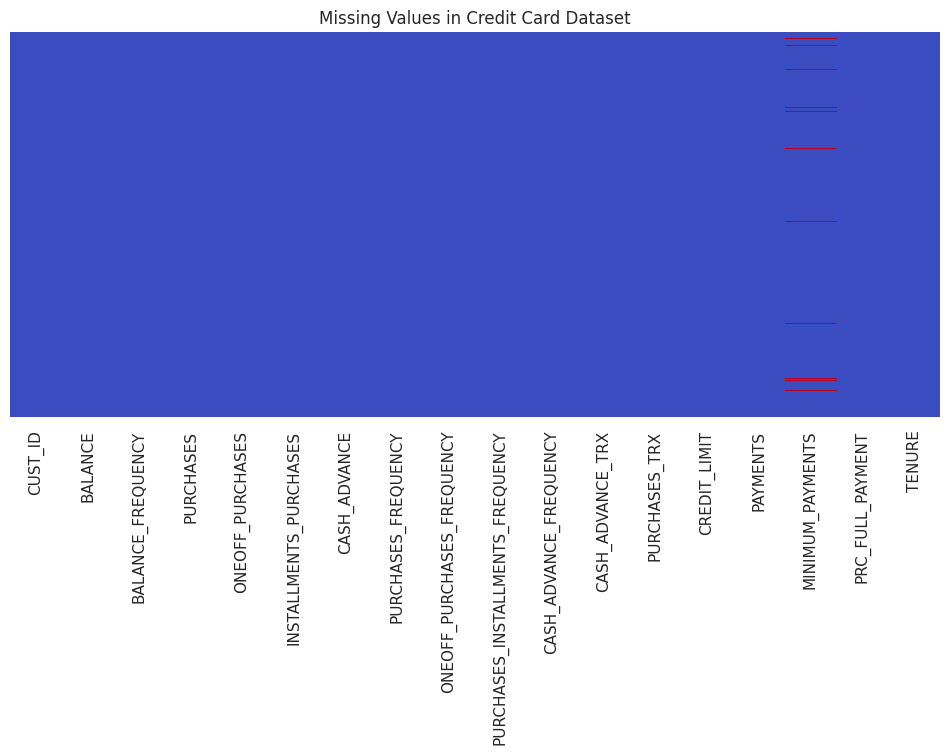

In [35]:
plt.figure(figsize=(12, 5))
sns.heatmap(df.isnull(), cbar=False,
            yticklabels=False,
          cmap='coolwarm')

plt.title("Missing Values in Credit Card Dataset")
plt.show()

In [36]:
data = df.copy()

# Remove duplicate records
data.drop_duplicates(inplace=True)

# Remove customer identification column
data.drop(columns=['CUST_ID'], inplace=True)

print("Customer ID removed.")
print("Duplicates removed.")

print("New Dataset Shape:", data.shape)

Customer ID removed.
Duplicates removed.
New Dataset Shape: (8950, 17)


In [38]:
imputer = SimpleImputer(strategy='median')
data = pd.DataFrame(imputer.fit_transform(data), columns=data.columns)
print("\nRemaining Missing Values:")
print(data.isnull().sum().sum())


Remaining Missing Values:
0


In [46]:
ids = df["CUST_ID"]
X = df.drop(columns="CUST_ID").copy()
features = X.columns.tolist()

In [54]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(data)
X_scaled_df = pd.DataFrame(X_scaled, columns=features)

print("\nScaled cleaned data -> mean ≈ 0, std ≈ 1")
print(X_scaled_df.agg(["mean", "std"]).T.round(3).head(6).to_string())


Scaled cleaned data -> mean ≈ 0, std ≈ 1
                        mean  std
BALANCE                  0.0  1.0
BALANCE_FREQUENCY        0.0  1.0
PURCHASES                0.0  1.0
ONEOFF_PURCHASES         0.0  1.0
INSTALLMENTS_PURCHASES   0.0  1.0
CASH_ADVANCE             0.0  1.0


In [55]:
q1, q3 = X.quantile(0.25), X.quantile(0.75)
iqr = q3 - q1
out_pct = (((X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)).mean() * 100).round(1)
summary = pd.DataFrame({"skewness": X.skew().round(2), "% IQR outliers": out_pct})
display(summary.sort_values("skewness", ascending=False))

,skewness,% IQR outliers
MINIMUM_PAYMENTS,13.62,9.4
ONEOFF_PURCHASES,10.05,11.3
PURCHASES,8.14,9.0
INSTALLMENTS_PURCHASES,7.30,9.7
PAYMENTS,5.91,9.0
CASH_ADVANCE_TRX,5.72,9.0
CASH_ADVANCE,5.17,11.5
PURCHASES_TRX,4.63,8.6
BALANCE,2.39,7.8
PRC_FULL_PAYMENT,1.94,16.5


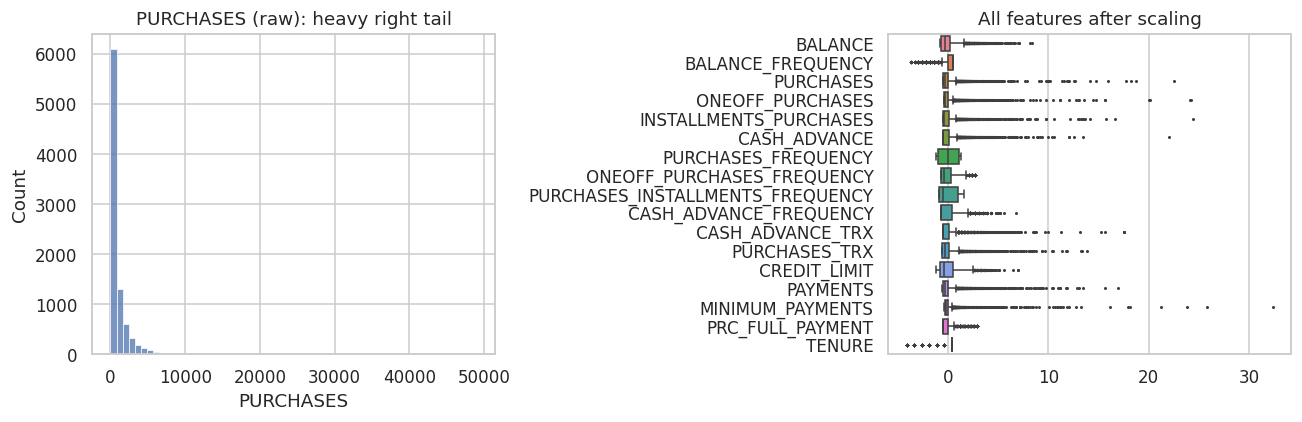

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(X["PURCHASES"], bins=60, ax=axes[0]); axes[0].set_title("PURCHASES (raw): heavy right tail")
sns.boxplot(data=X_scaled_df, orient="h", ax=axes[1], fliersize=1); axes[1].set_title("All features after scaling")
plt.tight_layout(); plt.show()

In [58]:
wcss, sil_km = [], []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    wcss.append(km.inertia_)
    sil_km.append(silhouette_score(X_scaled, km.labels_))

# Elbow point = point furthest from the straight line joining first and last point
ks = np.array(list(K_RANGE)); w = np.array(wcss)
# (axes normalised to 0-1 so that k and WCSS have comparable scale)
x_n = (ks - ks[0]) / (ks[-1] - ks[0]); y_n = (w - w.min()) / (w.max() - w.min())
k_elbow = int(ks[np.argmax((1 - x_n) - y_n)])
k_sil_km = int(ks[int(np.argmax(sil_km))])

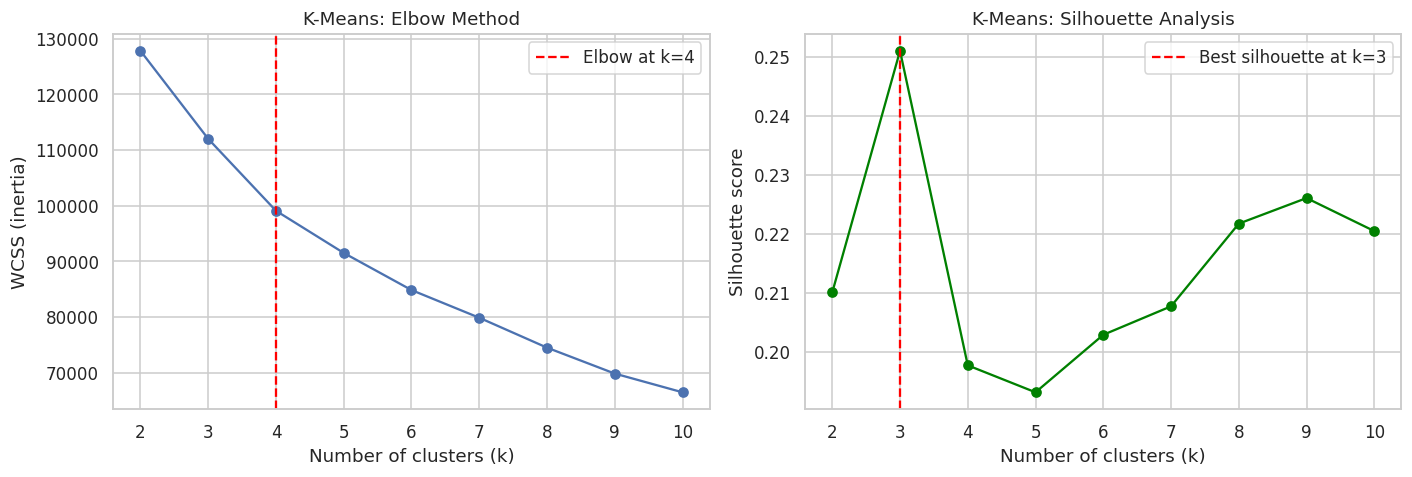

In [59]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(ks, wcss, "o-"); ax[0].axvline(k_elbow, ls="--", c="red", label=f"Elbow at k={k_elbow}")
ax[0].set_xlabel("Number of clusters (k)"); ax[0].set_ylabel("WCSS (inertia)"); ax[0].set_title("K-Means: Elbow Method"); ax[0].legend()
ax[1].plot(ks, sil_km, "o-", c="green"); ax[1].axvline(k_sil_km, ls="--", c="red", label=f"Best silhouette at k={k_sil_km}")
ax[1].set_xlabel("Number of clusters (k)"); ax[1].set_ylabel("Silhouette score"); ax[1].set_title("K-Means: Silhouette Analysis"); ax[1].legend()
plt.tight_layout(); plt.show()

In [60]:
pd.DataFrame({"k": ks, "WCSS": np.round(wcss, 0), "Silhouette": np.round(sil_km, 4)}).set_index("k")

,WCSS,Silhouette
k,,
2,127785.0,0.2100
3,111975.0,0.2510
4,99062.0,0.1977
5,91490.0,0.1931
6,84827.0,0.2029
7,79856.0,0.2077
8,74485.0,0.2217
9,69829.0,0.2260
10,66466.0,0.2204


In [63]:
K = 3
kmeans = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(X_scaled)
km_labels = kmeans.labels_
print("K-Means cluster sizes:", dict(zip(*np.unique(km_labels, return_counts=True))))

K-Means cluster sizes: {np.int32(0): np.int64(6119), np.int32(1): np.int64(1235), np.int32(2): np.int64(1596)}


Variance explained by PC1+PC2: 47.6%


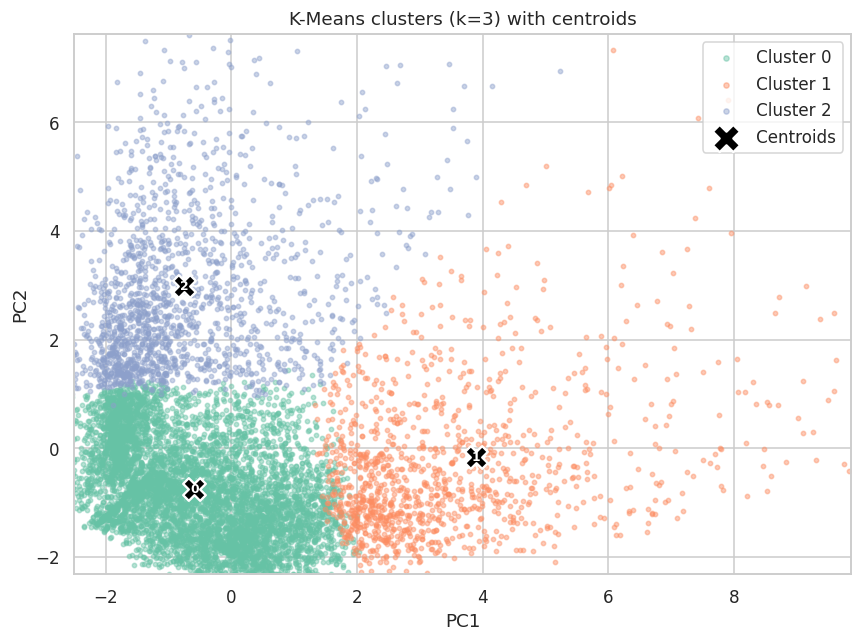

In [64]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
Z = pca.fit_transform(X_scaled)
print("Variance explained by PC1+PC2: %.1f%%" % (pca.explained_variance_ratio_.sum() * 100))

def plot_clusters(Z, labels, centers_2d, title, marker_label):
    fig, ax = plt.subplots(figsize=(8, 6))
    palette = sns.color_palette("Set2", len(np.unique(labels)))
    for c in np.unique(labels):
        ax.scatter(Z[labels == c, 0], Z[labels == c, 1], s=8, alpha=0.45, color=palette[c], label=f"Cluster {c}")
    ax.scatter(centers_2d[:, 0], centers_2d[:, 1], c="black", marker="X", s=220, edgecolor="white", linewidth=1.5, label=marker_label)
    for i, (x, y) in enumerate(centers_2d):
        ax.annotate(str(i), (x, y), color="white", ha="center", va="center", fontsize=8, fontweight="bold")
    ax.set_xlim(*np.percentile(Z[:, 0], [0.5, 99.5])); ax.set_ylim(*np.percentile(Z[:, 1], [0.5, 99.5]))
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title(title); ax.legend(markerscale=1.2, loc="upper right")
    plt.tight_layout(); plt.show()

plot_clusters(Z, km_labels, pca.transform(kmeans.cluster_centers_), f"K-Means clusters (k={K}) with centroids", "Centroids")

In [65]:
centroids_orig = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=features).round(2)
centroids_orig.index.name = "Cluster"
centroids_orig["Size"] = np.bincount(km_labels)
display(centroids_orig.T)

Cluster,0,1,2
BALANCE,799.75,2228.03,3984.03
BALANCE_FREQUENCY,0.84,0.98,0.96
PURCHASES,505.53,4267.53,382.86
ONEOFF_PURCHASES,253.12,2716.45,248.24
INSTALLMENTS_PURCHASES,252.73,1551.56,134.70
CASH_ADVANCE,330.82,460.63,3866.64
PURCHASES_FREQUENCY,0.47,0.95,0.23
ONEOFF_PURCHASES_FREQUENCY,0.13,0.67,0.11
PURCHASES_INSTALLMENTS_FREQUENCY,0.35,0.74,0.14
CASH_ADVANCE_FREQUENCY,0.07,0.06,0.45


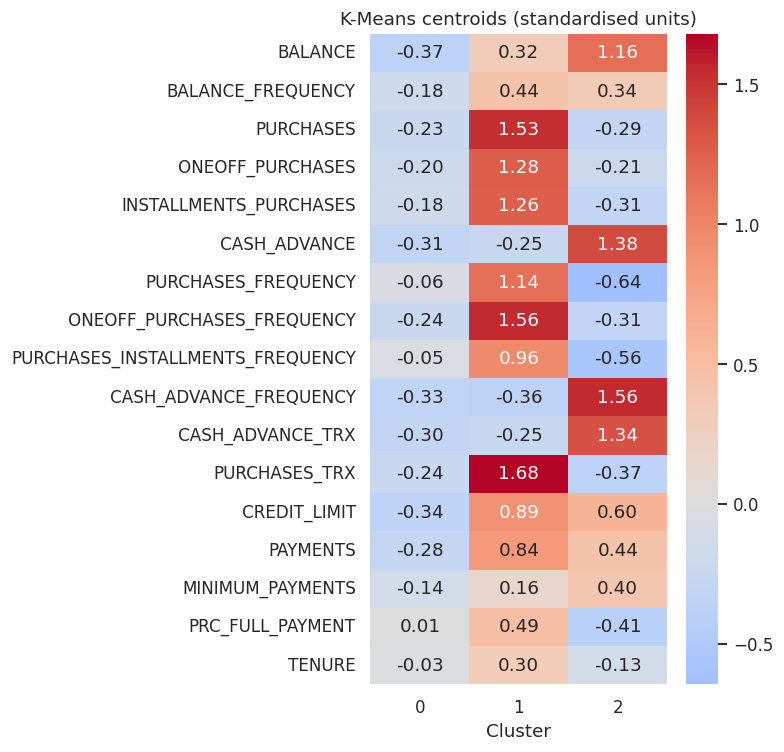

In [66]:
plt.figure(figsize=(7, 7))
sns.heatmap(pd.DataFrame(kmeans.cluster_centers_, columns=features).T, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("K-Means centroids (standardised units)"); plt.xlabel("Cluster"); plt.tight_layout(); plt.show()

In [67]:
cost_med, sil_med = [], []
for k in K_RANGE:
    kmed = KMedoids(n_clusters=k, method="alternate", init="k-medoids++", max_iter=200, random_state=RANDOM_STATE).fit(X_scaled)
    cost_med.append(kmed.inertia_)
    sil_med.append(silhouette_score(X_scaled, kmed.labels_))

k_sil_med = int(ks[int(np.argmax(sil_med))])

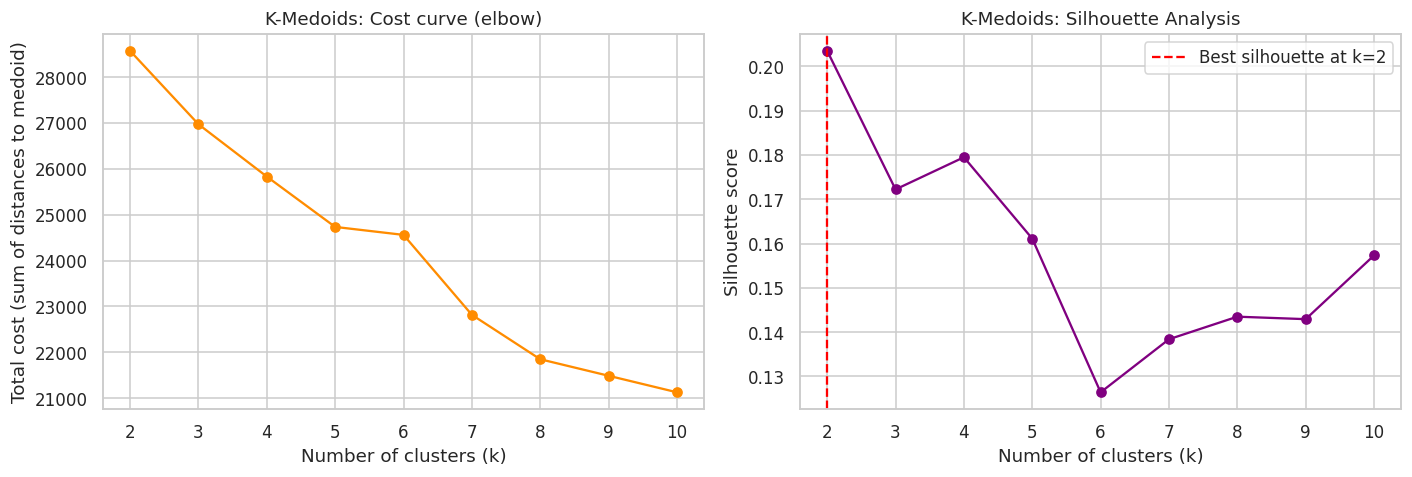

In [68]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(ks, cost_med, "o-", c="darkorange")
ax[0].set_xlabel("Number of clusters (k)"); ax[0].set_ylabel("Total cost (sum of distances to medoid)"); ax[0].set_title("K-Medoids: Cost curve (elbow)")
ax[1].plot(ks, sil_med, "o-", c="purple"); ax[1].axvline(k_sil_med, ls="--", c="red", label=f"Best silhouette at k={k_sil_med}")
ax[1].set_xlabel("Number of clusters (k)"); ax[1].set_ylabel("Silhouette score"); ax[1].set_title("K-Medoids: Silhouette Analysis"); ax[1].legend()
plt.tight_layout(); plt.show()


In [69]:
pd.DataFrame({"k": ks, "Total cost": np.round(cost_med, 0), "Silhouette": np.round(sil_med, 4)}).set_index("k")

,Total cost,Silhouette
k,,
2,28573.0,0.2035
3,26972.0,0.1722
4,25832.0,0.1795
5,24734.0,0.1611
6,24561.0,0.1264
7,22818.0,0.1384
8,21850.0,0.1435
9,21490.0,0.1429
10,21129.0,0.1573


In [70]:
kmedoids = KMedoids(n_clusters=K, method="alternate", init="k-medoids++", max_iter=300, random_state=RANDOM_STATE).fit(X_scaled)
med_labels = kmedoids.labels_
print("K-Medoids cluster sizes:", dict(zip(*np.unique(med_labels, return_counts=True))))

K-Medoids cluster sizes: {np.int64(0): np.int64(4114), np.int64(1): np.int64(3504), np.int64(2): np.int64(1332)}


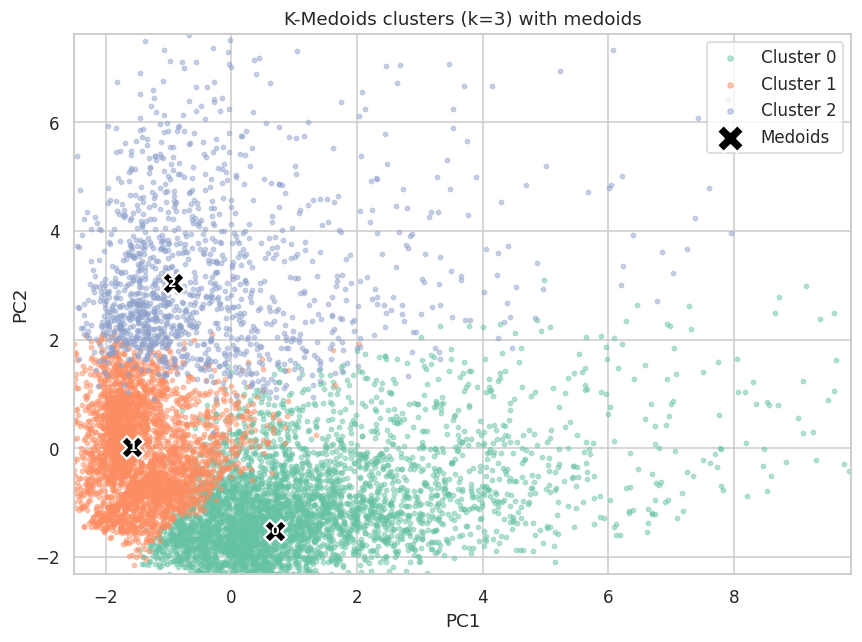

In [71]:
plot_clusters(Z, med_labels, pca.transform(kmedoids.cluster_centers_), f"K-Medoids clusters (k={K}) with medoids", "Medoids")

In [72]:
medoid_idx = kmedoids.medoid_indices_
medoids_orig = X.iloc[medoid_idx].round(2).copy()
medoids_orig.index = [f"Cluster {i}" for i in range(K)]
medoids_orig["Size"] = np.bincount(med_labels)
medoids_orig["CUST_ID"] = ids.iloc[medoid_idx].values
display(medoids_orig.T)

,Cluster 0,Cluster 1,Cluster 2
BALANCE,109.47,1382.38,4202.17
BALANCE_FREQUENCY,1.0,1.0,1.0
PURCHASES,1251.26,77.91,462.0
ONEOFF_PURCHASES,635.79,0.0,462.0
INSTALLMENTS_PURCHASES,615.47,77.91,0.0
CASH_ADVANCE,0.0,300.53,4776.1
PURCHASES_FREQUENCY,0.83,0.08,0.17
ONEOFF_PURCHASES_FREQUENCY,0.25,0.0,0.17
PURCHASES_INSTALLMENTS_FREQUENCY,0.67,0.08,0.0
CASH_ADVANCE_FREQUENCY,0.0,0.17,0.42


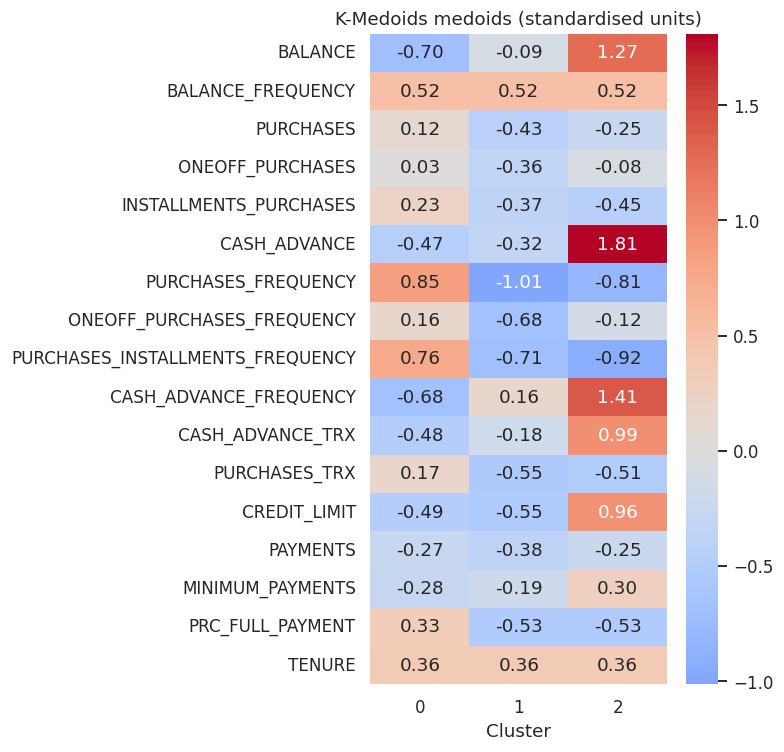

In [73]:
plt.figure(figsize=(7, 7))
sns.heatmap(pd.DataFrame(kmedoids.cluster_centers_, columns=features).T, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("K-Medoids medoids (standardised units)"); plt.xlabel("Cluster"); plt.tight_layout(); plt.show()

In [74]:
def evaluate(X_, labels):
    return {"Silhouette (higher better)": silhouette_score(X_, labels),
            "Davies-Bouldin (lower better)": davies_bouldin_score(X_, labels),
            "Calinski-Harabasz (higher better)": calinski_harabasz_score(X_, labels)}

comparison = pd.DataFrame({"K-Means": evaluate(X_scaled, km_labels), "K-Medoids": evaluate(X_scaled, med_labels)}).T
comparison["Inertia / Total cost"] = [kmeans.inertia_, kmedoids.inertia_]
comparison["Cluster sizes"] = [str(np.bincount(km_labels).tolist()), str(np.bincount(med_labels).tolist())]
display(comparison.round(4))

# winner per metric
print("Best per metric:")
print(" Silhouette        ->", comparison["Silhouette (higher better)"].idxmax())
print(" Davies-Bouldin    ->", comparison["Davies-Bouldin (lower better)"].idxmin())
print(" Calinski-Harabasz ->", comparison["Calinski-Harabasz (higher better)"].idxmax())

,Silhouette (higher better),Davies-Bouldin (lower better),Calinski-Harabasz (higher better),Inertia / Total cost,Cluster sizes
K-Means,0.2506,1.5968,1605.0855,111973.9734,"[6119, 1235, 1596]"
K-Medoids,0.1722,1.6684,1468.2275,26972.3826,"[4114, 3504, 1332]"


Best per metric:
 Silhouette        -> K-Means
 Davies-Bouldin    -> K-Means
 Calinski-Harabasz -> K-Means


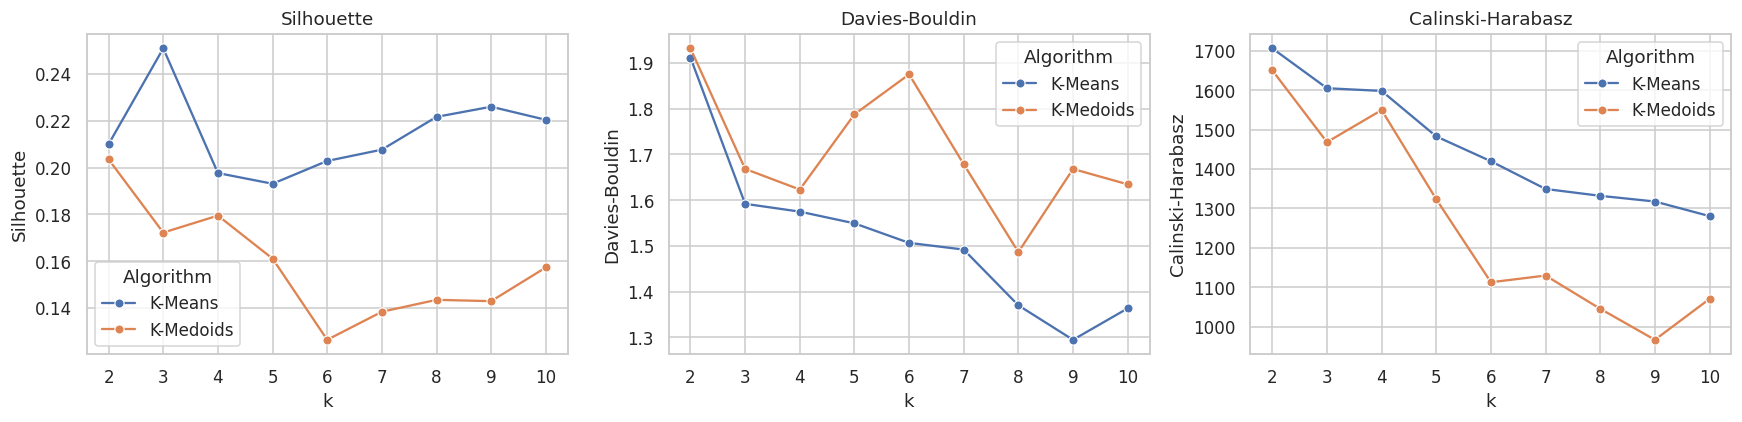

Silhouette           Davies-Bouldin           Calinski-Harabasz  \
Algorithm    K-Means K-Medoids        K-Means K-Medoids           K-Means   
k                                                                           
2              0.210     0.204          1.912     1.932          1706.179   
3              0.251     0.172          1.592     1.668          1605.026   
4              0.198     0.179          1.575     1.623          1598.077   
5              0.193     0.161          1.549     1.788          1482.668   
6              0.203     0.126          1.506     1.875          1419.699   
7              0.208     0.138          1.492     1.679          1349.351   
8              0.222     0.143          1.370     1.486          1331.973   
9              0.226     0.143          1.294     1.668          1317.572   
10             0.220     0.157          1.363     1.635          1280.532   

                     
Algorithm K-Medoids  
k                    
2          1650.252  
3          1468.227  
4          1549.552  
5          1323.269  
6          1112.705  
7          1129.697  
8          1045.359  
9           966.682  
10         1070.457

In [75]:
rows = []
for k in K_RANGE:
    a = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled).labels_
    b = KMedoids(n_clusters=k, method="alternate", init="k-medoids++", max_iter=200, random_state=RANDOM_STATE).fit(X_scaled).labels_
    for name, lab in [("K-Means", a), ("K-Medoids", b)]:
        e = evaluate(X_scaled, lab)
        rows.append({"k": k, "Algorithm": name, "Silhouette": e["Silhouette (higher better)"],
                     "Davies-Bouldin": e["Davies-Bouldin (lower better)"], "Calinski-Harabasz": e["Calinski-Harabasz (higher better)"]})
allk = pd.DataFrame(rows)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a_, m in zip(ax, ["Silhouette", "Davies-Bouldin", "Calinski-Harabasz"]):
    sns.lineplot(data=allk, x="k", y=m, hue="Algorithm", marker="o", ax=a_); a_.set_title(m)
plt.tight_layout(); plt.show()
allk.pivot(index="k", columns="Algorithm").round(3)

In [76]:
D = np.linalg.norm(kmeans.cluster_centers_[:, None, :] - kmedoids.cluster_centers_[None, :, :], axis=2)
r, c_ = linear_sum_assignment(D)
match = pd.DataFrame({"K-Means cluster": r, "Matched K-Medoids cluster": c_, "Distance (std. units)": D[r, c_].round(3),
                      "K-Means size": np.bincount(km_labels)[r], "K-Medoids size": np.bincount(med_labels)[c_]})
display(match)


nearest = [np.linalg.norm(X_scaled - ctr, axis=1).min() for ctr in kmeans.cluster_centers_]
print("\nDistance from each K-Means centroid to the nearest real customer:", np.round(nearest, 3))
print("Distance from each K-Medoids medoid to the nearest real customer: ", np.round([0.0]*K, 3), "(medoids ARE real customers)")



,K-Means cluster,Matched K-Medoids cluster,Distance (std. units),K-Means size,K-Medoids size
0,0,1,1.744,6119,3504
1,1,0,3.687,1235,4114
2,2,2,1.227,1596,1332



Distance from each K-Means centroid to the nearest real customer: [0.85  1.343 1.227]
Distance from each K-Medoids medoid to the nearest real customer:  [0. 0. 0.] (medoids ARE real customers)


In [77]:
mapping = dict(zip(c_, r))
med_aligned = np.array([mapping[l] for l in med_labels])
print("Adjusted Rand Index between K-Means and K-Medoids partitions: %.3f" % adjusted_rand_score(km_labels, med_labels))
print("Customers assigned to the matched cluster by both algorithms: %.1f%%" % ((med_aligned == km_labels).mean() * 100))

Adjusted Rand Index between K-Means and K-Medoids partitions: 0.277
Customers assigned to the matched cluster by both algorithms: 62.3%


In [78]:
nearest = [np.linalg.norm(X_scaled - ctr, axis=1).min() for ctr in kmeans.cluster_centers_]
print("\nDistance from each K-Means centroid to the nearest real customer:", np.round(nearest, 3))
print("Distance from each K-Medoids medoid to the nearest real customer: ", np.round([0.0]*K, 3), "(medoids ARE real customers)")


Distance from each K-Means centroid to the nearest real customer: [0.85  1.343 1.227]
Distance from each K-Medoids medoid to the nearest real customer:  [0. 0. 0.] (medoids ARE real customers)


In [79]:
side = pd.concat({"K-Means centroid": centroids_orig.drop(columns="Size").iloc[r].reset_index(drop=True),
                  "K-Medoids medoid": medoids_orig.drop(columns=["Size", "CUST_ID"]).iloc[c_].reset_index(drop=True).astype(float)}, axis=1)
display(side.T.round(1))

0       1       2
K-Means centroid BALANCE                            799.8  2228.0  3984.0
                 BALANCE_FREQUENCY                    0.8     1.0     1.0
                 PURCHASES                          505.5  4267.5   382.9
                 ONEOFF_PURCHASES                   253.1  2716.4   248.2
                 INSTALLMENTS_PURCHASES             252.7  1551.6   134.7
                 CASH_ADVANCE                       330.8   460.6  3866.6
                 PURCHASES_FREQUENCY                  0.5     1.0     0.2
                 ONEOFF_PURCHASES_FREQUENCY           0.1     0.7     0.1
                 PURCHASES_INSTALLMENTS_FREQUENCY     0.4     0.7     0.1
                 CASH_ADVANCE_FREQUENCY               0.1     0.1     0.4
                 CASH_ADVANCE_TRX                     1.2     1.5    12.4
                 PURCHASES_TRX                        8.6    56.5     5.6
                 CREDIT_LIMIT                      3271.5  7738.2  6671.5
                 PAYMENTS                           909.7  4151.3  3018.4
                 MINIMUM_PAYMENTS                   523.2  1222.2  1786.7
                 PRC_FULL_PAYMENT                     0.2     0.3     0.0
                 TENURE                              11.5    11.9    11.4
K-Medoids medoid BALANCE                           1382.4   109.5  4202.2
                 BALANCE_FREQUENCY                    1.0     1.0     1.0
                 PURCHASES                           77.9  1251.3   462.0
                 ONEOFF_PURCHASES                     0.0   635.8   462.0
                 INSTALLMENTS_PURCHASES              77.9   615.5     0.0
                 CASH_ADVANCE                       300.5     0.0  4776.1
                 PURCHASES_FREQUENCY                  0.1     0.8     0.2
                 ONEOFF_PURCHASES_FREQUENCY           0.0     0.2     0.2
                 PURCHASES_INSTALLMENTS_FREQUENCY     0.1     0.7     0.0
                 CASH_ADVANCE_FREQUENCY               0.2     0.0     0.4
                 CASH_ADVANCE_TRX                     2.0     0.0    10.0
                 PURCHASES_TRX                        1.0    19.0     2.0
                 CREDIT_LIMIT                      2500.0  2700.0  8000.0
                 PAYMENTS                           639.4   958.9  1010.8
                 MINIMUM_PAYMENTS                   397.8   187.6  1541.8
                 PRC_FULL_PAYMENT                     0.0     0.2     0.0
                 TENURE                              12.0    12.0    12.0

In [80]:
extreme = (np.abs(X_scaled) > 5).any(axis=1)
print(f"Extreme customers (|z| > 5 on at least one feature): {extreme.sum()} ({extreme.mean()*100:.1f}%)")

dist = pd.DataFrame({
    "K-Means: all": np.bincount(km_labels, minlength=K),
    "K-Means: extreme": np.bincount(km_labels[extreme], minlength=K),
    "K-Medoids: all": np.bincount(med_labels, minlength=K),
    "K-Medoids: extreme": np.bincount(med_labels[extreme], minlength=K)})
dist.index.name = "Cluster"
display(dist)

Extreme customers (|z| > 5 on at least one feature): 307 (3.4%)


,K-Means: all,K-Means: extreme,K-Medoids: all,K-Medoids: extreme
Cluster,,,,
0,6119,18,4114,126
1,1235,144,3504,16
2,1596,145,1332,165


In [81]:
Xin = X_scaled[~extreme]
km_in = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(Xin)
md_in = KMedoids(n_clusters=K, method="alternate", init="k-medoids++", max_iter=300, random_state=RANDOM_STATE).fit(Xin)

def mean_shift(full_centers, in_centers):
    Dm = np.linalg.norm(full_centers[:, None, :] - in_centers[None, :, :], axis=2)
    i, j = linear_sum_assignment(Dm)
    return Dm[i, j]

s_km = mean_shift(kmeans.cluster_centers_, km_in.cluster_centers_)
s_md = mean_shift(kmedoids.cluster_centers_, md_in.cluster_centers_)
shift = pd.DataFrame({"K-Means centre shift": s_km, "K-Medoids centre shift": s_md}).round(3)
shift.loc["Average"] = shift.mean().round(3)
display(shift)

,K-Means centre shift,K-Medoids centre shift
0,0.981,1.948
1,2.783,2.576
2,0.401,2.726
Average,1.388,2.417


Silhouette on non-extreme customers:  K-Means 0.2028 | K-Medoids 0.1778
Silhouette on all customers:          K-Means 0.2506 | K-Medoids 0.1722


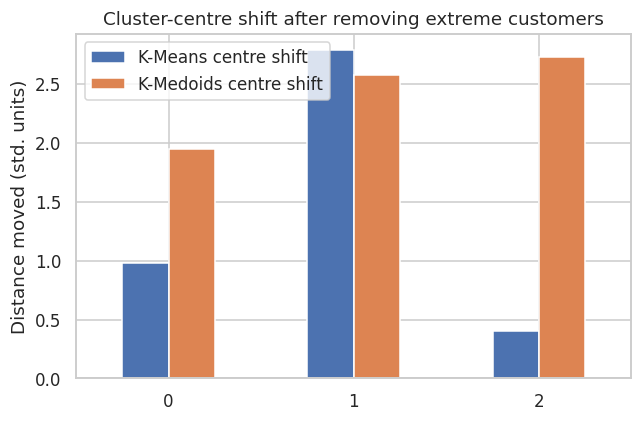

In [82]:
print("Silhouette on non-extreme customers:  K-Means %.4f | K-Medoids %.4f" % (
    silhouette_score(Xin, km_in.labels_), silhouette_score(Xin, md_in.labels_)))
print("Silhouette on all customers:          K-Means %.4f | K-Medoids %.4f" % (
    silhouette_score(X_scaled, km_labels), silhouette_score(X_scaled, med_labels)))

fig, ax = plt.subplots(figsize=(6, 4))
shift.iloc[:-1].plot(kind="bar", ax=ax); ax.set_ylabel("Distance moved (std. units)")
ax.set_title("Cluster-centre shift after removing extreme customers"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

In [83]:
profile = X.copy(); profile["KMeans"] = km_labels; profile["KMedoids"] = med_labels
key = ["BALANCE", "PURCHASES", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES", "CASH_ADVANCE", "PURCHASES_FREQUENCY",
       "CASH_ADVANCE_FREQUENCY", "CREDIT_LIMIT", "PAYMENTS", "PRC_FULL_PAYMENT"]
print("=== K-Means cluster profile (cluster MEAN) ===")
display(profile.groupby("KMeans")[key].mean().round(2).assign(Size=np.bincount(km_labels)))
print("=== K-Medoids cluster profile (cluster MEDIAN) ===")
display(profile.groupby("KMedoids")[key].median().round(2).assign(Size=np.bincount(med_labels)))

=== K-Means cluster profile (cluster MEAN) ===


,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,CASH_ADVANCE_FREQUENCY,CREDIT_LIMIT,PAYMENTS,PRC_FULL_PAYMENT,Size
KMeans,,,,,,,,,,,
0,799.75,505.53,253.12,252.73,330.82,0.47,0.07,3271.56,909.68,0.16,6119
1,2220.00,4268.52,2717.83,1551.18,458.42,0.95,0.06,7733.97,4151.28,0.30,1235
2,3989.14,384.53,248.72,135.89,3866.21,0.23,0.45,6675.44,3019.11,0.03,1596


=== K-Medoids cluster profile (cluster MEDIAN) ===


,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,CASH_ADVANCE_FREQUENCY,CREDIT_LIMIT,PAYMENTS,PRC_FULL_PAYMENT,Size
KMedoids,,,,,,,,,,,
0,346.22,939.04,241.64,449.88,0.00,0.92,0.00,3500.0,1002.77,0.08,4114
1,896.46,53.22,0.00,0.00,185.45,0.08,0.08,2500.0,534.78,0.00,3504
2,4258.29,117.12,0.00,0.00,3597.66,0.08,0.42,7500.0,1924.94,0.00,1332
